In [2]:

from roboflow import Roboflow
from getpass import getpass

# Menghubungkan ke Roboflow
rf = Roboflow(api_key=getpass("API Key: "))

# Memilih dataset Acne Severity Classification
project = rf.workspace("taschenbier").project("acne-severity-classification")

# Download dataset versi 3
dataset = project.version(3).download("folder")

print("Dataset berhasil diunduh!")
print("Lokasi dataset:", dataset.location)


loading Roboflow workspace...
loading Roboflow project...
Dataset berhasil diunduh!
Lokasi dataset: c:\Users\damar\KULIAH\S5\PemMes\testing\Acne-Severity-Classification-3


In [3]:

from pathlib import Path

# Mengambil lokasi dataset secara otomatis
data_dir = Path(dataset.location)

# Menampilkan isi folder dataset
print("Isi folder dataset:")

for folder in sorted(data_dir.iterdir()):
    print(folder.name)


Isi folder dataset:
README.dataset.txt
README.roboflow.txt
test
train
valid


In [4]:

import pandas as pd

# Menyimpan hasil perhitungan
data = []

# Membaca folder train, valid, dan test
for split in ["train", "valid", "test"]:
    folder = data_dir / split

    # Membaca setiap kelas
    for kelas in sorted(folder.iterdir()):
        if kelas.is_dir():

            # Menghitung jumlah gambar
            gambar = list(kelas.glob("*.jpg"))
            gambar += list(kelas.glob("*.png"))
            gambar += list(kelas.glob("*.jpeg"))

            data.append({
                "Split": split,
                "Kelas": kelas.name,
                "Jumlah": len(gambar)
            })

# Membuat DataFrame
df = pd.DataFrame(data)

# Membuat tabel distribusi kelas
distribusi = df.pivot(
    index="Kelas",
    columns="Split",
    values="Jumlah"
).fillna(0).astype(int)

display(distribusi)

print("Total gambar:", df["Jumlah"].sum())


Split,test,train,valid
Kelas,,,
IGA0,30,1113,78
IGA1,20,1257,48
IGA2,58,2730,136
IGA3,16,501,34
IGA4,11,390,29


Total gambar: 6451


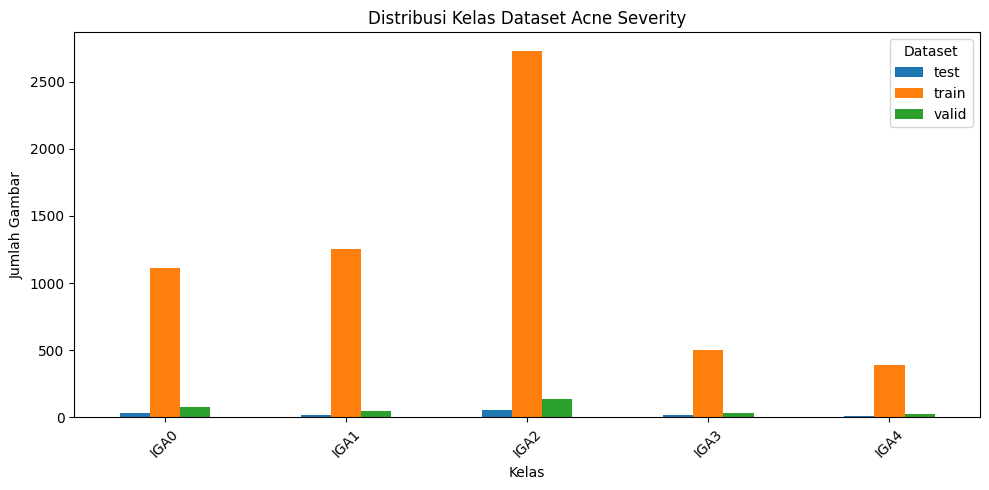

In [5]:

import matplotlib.pyplot as plt

# Membuat grafik distribusi kelas
distribusi.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribusi Kelas Dataset Acne Severity")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()


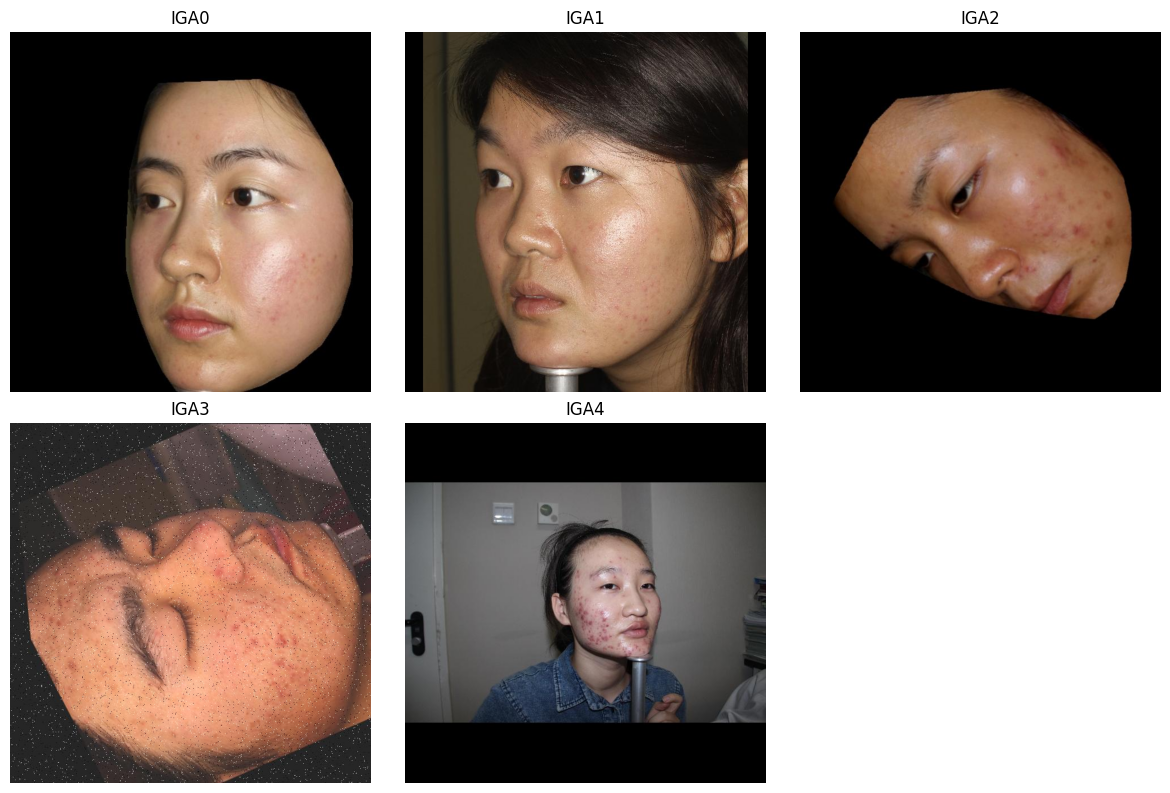

In [7]:

from PIL import Image
import matplotlib.pyplot as plt
import random

# Mengambil folder training
train_dir = data_dir / "train"

# Mendapatkan daftar kelas
kelas = sorted([
    folder for folder in train_dir.iterdir()
    if folder.is_dir()
])

# Membuat tampilan 2 baris dan 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, folder in zip(axes.flat, kelas):

    # Mengambil gambar dari setiap kelas
    gambar = list(folder.glob("*.jpg"))
    gambar += list(folder.glob("*.png"))
    gambar += list(folder.glob("*.jpeg"))

    # Menampilkan satu gambar secara acak
    if gambar:
        with Image.open(random.choice(gambar)) as img:
            ax.imshow(img.convert("RGB"))

    ax.set_title(folder.name)
    ax.axis("off")

# Menghapus subplot yang tidak digunakan
for ax in axes.flat[len(kelas):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()


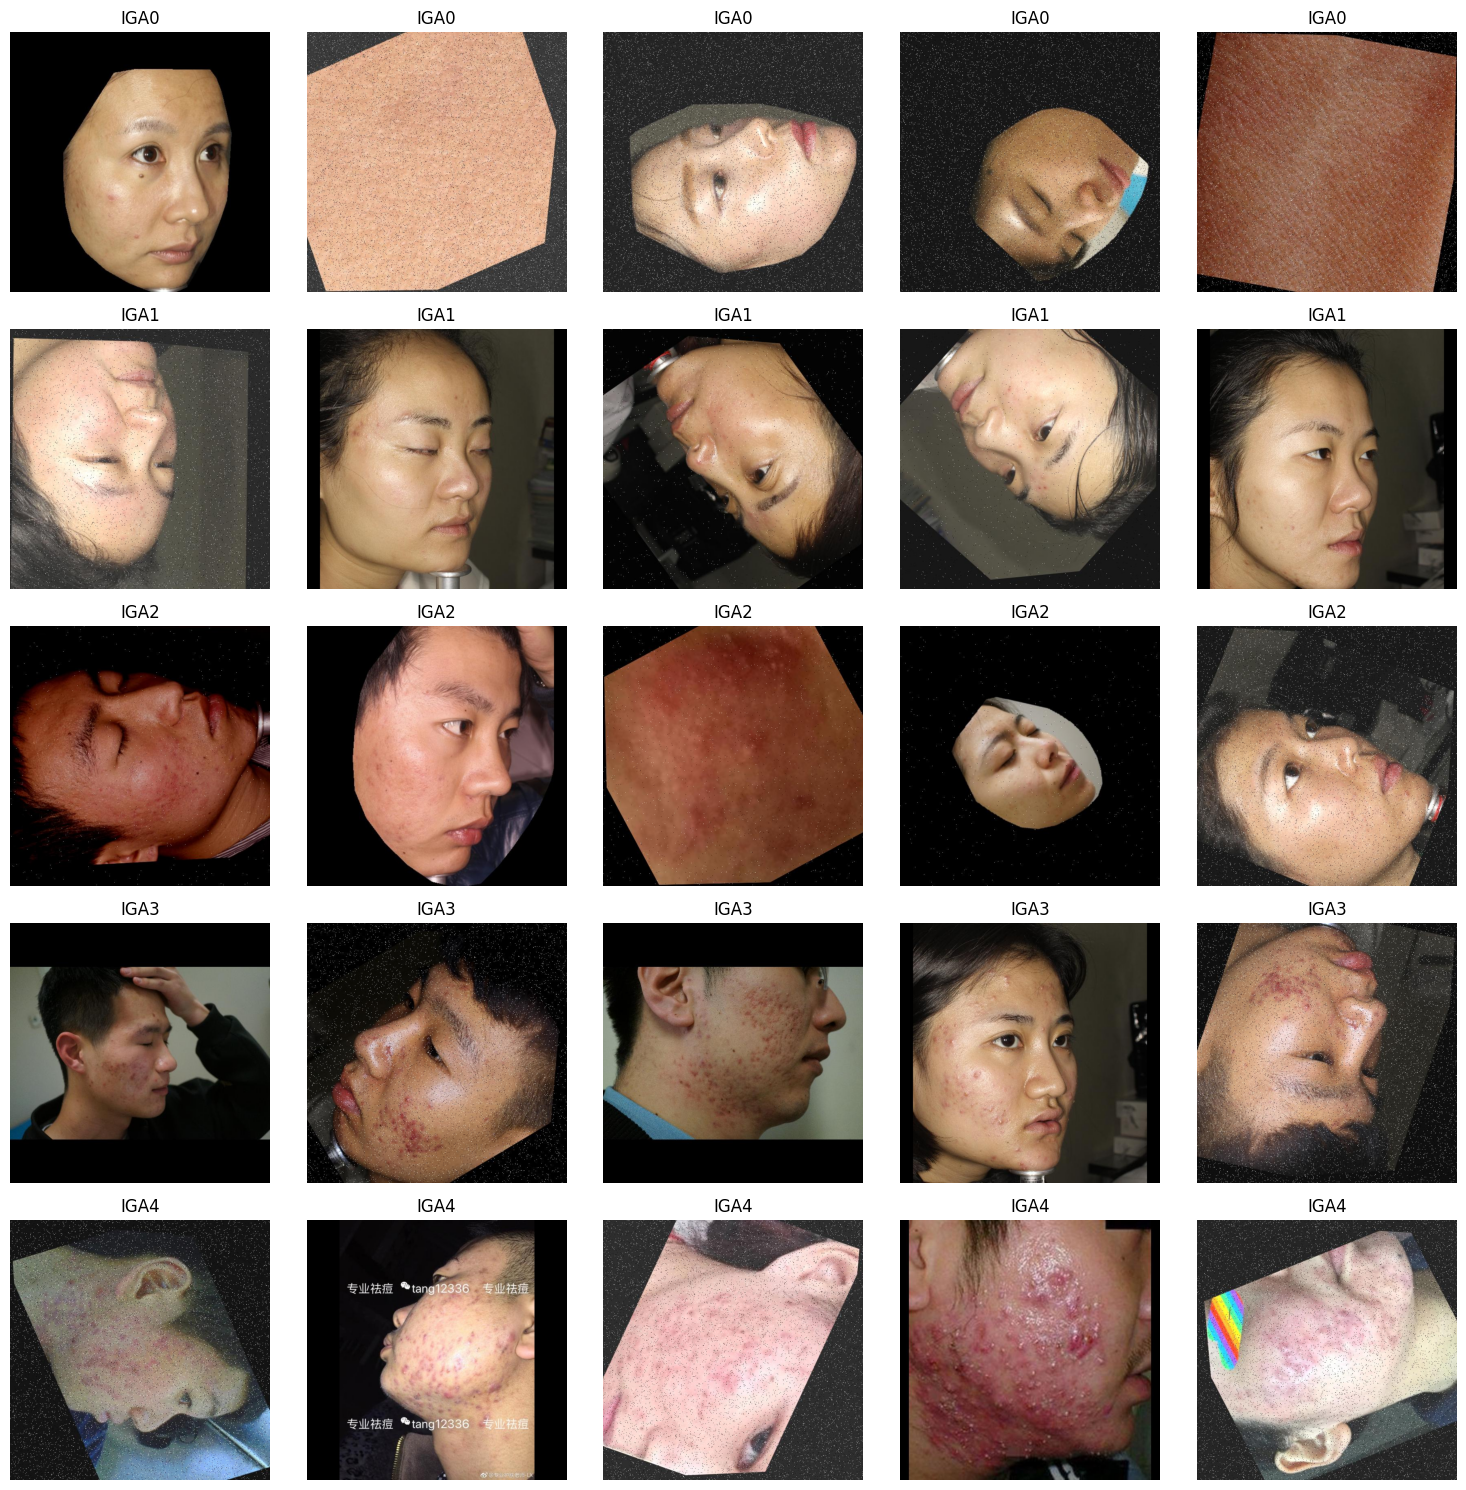

In [8]:

# Menampilkan 5 gambar dari setiap kelas
fig, axes = plt.subplots(len(kelas), 5, figsize=(15, 3 * len(kelas)))

for i, folder in enumerate(kelas):

    gambar = list(folder.glob("*.jpg"))
    gambar += list(folder.glob("*.png"))
    gambar += list(folder.glob("*.jpeg"))

    # Mengambil 5 gambar secara acak
    sampel = random.sample(gambar, min(5, len(gambar)))

    for j in range(5):
        ax = axes[i, j]

        if j < len(sampel):
            with Image.open(sampel[j]) as img:
                ax.imshow(img.convert("RGB"))
        else:
            ax.axis("off")
            continue

        ax.set_title(folder.name)
        ax.axis("off")

plt.tight_layout()
plt.show()


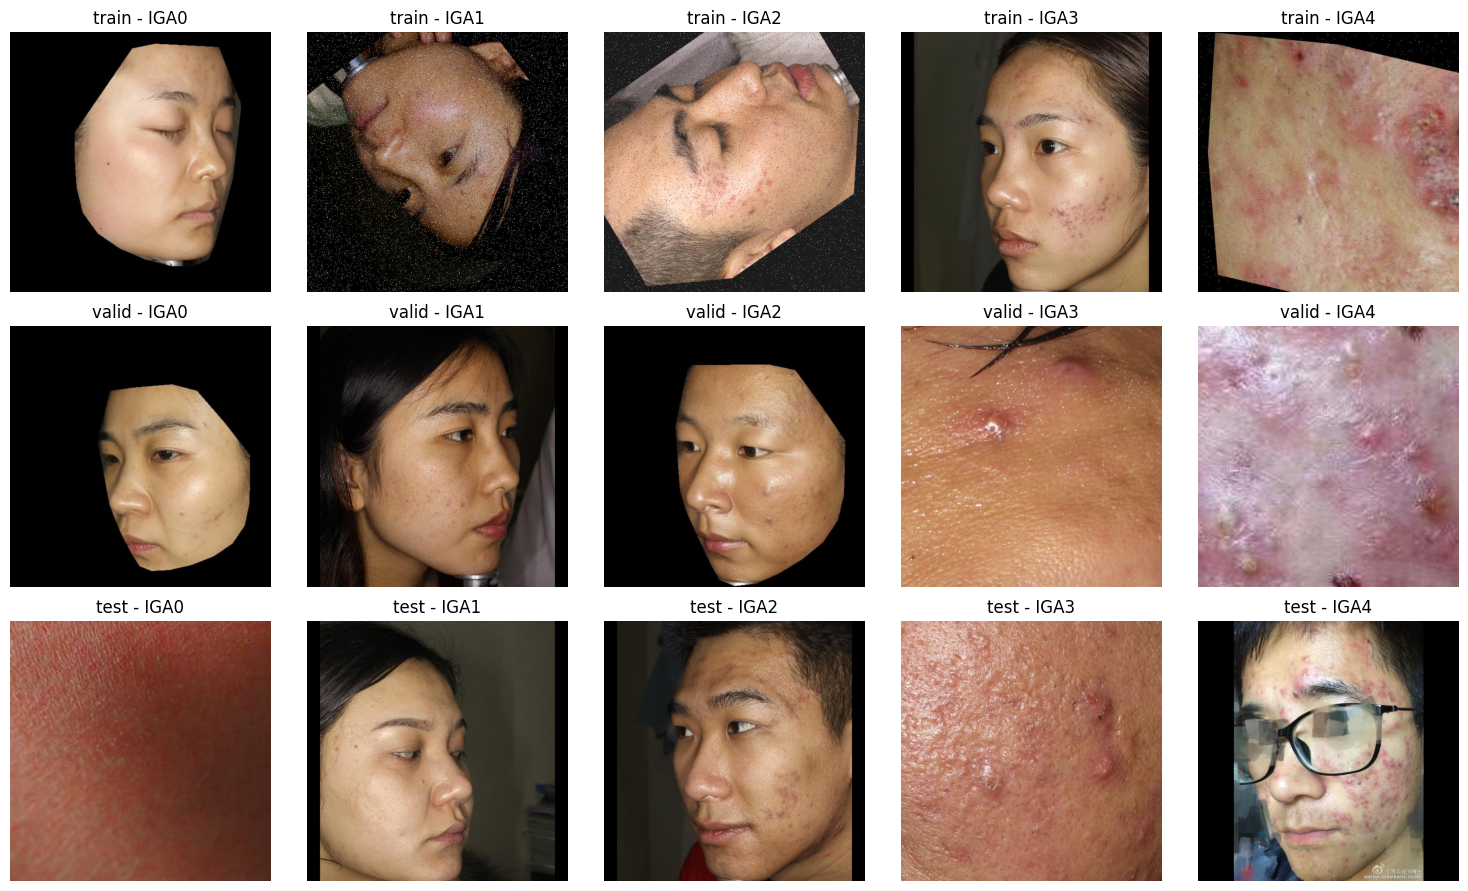

In [8]:

import matplotlib.pyplot as plt
from PIL import Image
import random

# Daftar pembagian dataset
splits = ["train", "valid", "test"]

# Mengambil nama kelas
kelas = sorted([
    folder.name for folder in (data_dir / "train").iterdir()
    if folder.is_dir()
])

# Menampilkan 3 baris (split) dan 5 kolom (kelas)
fig, axes = plt.subplots(3, len(kelas), figsize=(15, 9))

for i, split in enumerate(splits):
    for j, nama_kelas in enumerate(kelas):

        folder = data_dir / split / nama_kelas

        # Mengambil daftar gambar
        gambar = (
            list(folder.glob("*.jpg")) +
            list(folder.glob("*.png")) +
            list(folder.glob("*.jpeg"))
        )

        if gambar:
            with Image.open(random.choice(gambar)) as img:
                axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(f"{split} - {nama_kelas}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [9]:

from collections import defaultdict

# Menyimpan asal gambar dan split-nya
asal_gambar = defaultdict(set)

for split in ["train", "valid", "test"]:
    folder = data_dir / split

    for file in folder.rglob("*"):
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            # Mengambil nama gambar sebelum akhiran .rf.
            nama_asli = file.name.split(".rf.")[0]

            # Mencatat lokasi gambar
            asal_gambar[(file.parent.name, nama_asli)].add(split)

# Mencari gambar yang muncul pada lebih dari satu split
duplikat = [
    (nama, splits)
    for nama, splits in asal_gambar.items()
    if len(splits) > 1
]

print("Jumlah indikasi gambar lintas split:", len(duplikat))
print("Contoh:", duplikat[:5])


Jumlah indikasi gambar lintas split: 133
Contoh: [(('IGA2', 'levle1_100_jpg'), {'train', 'valid'}), (('IGA2', 'levle1_102_jpg'), {'train', 'valid'}), (('IGA2', 'levle1_108_jpg'), {'train', 'valid'}), (('IGA2', 'levle1_139_jpg'), {'train', 'test'}), (('IGA2', 'levle1_140_jpg'), {'train', 'valid'})]


In [10]:

%pip install tensorflow


^C
Note: you may need to restart the kernel to use updated packages.


  Using cached tensorflow-2.21.0-cp310-cp310-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.1-cp310-cp310-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.84.0-cp310-cp310-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.12.4-py3-none-any.whl.metadata (6.0 kB)
  Using cached h5py-3.14.0-cp310-cp310-win_amd64.whl.metadata (2.7 kB)
  Using cached m

In [19]:
import tensorflow as tf

# Parameter dataset
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# Mengambil nama kelas
kelas = sorted([
    folder.name
    for folder in (data_dir / "train").iterdir()
    if folder.is_dir()
])

# Memuat data training
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=kelas,
    shuffle=True,
    seed=42
)

# Memuat data validation
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=kelas,
    shuffle=False
)

# Memuat data testing
test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=kelas,
    shuffle=False
)

print("\nDaftar kelas:", kelas)


Found 5607 files belonging to 5 classes.
Found 311 files belonging to 5 classes.
Found 134 files belonging to 5 classes.

Daftar kelas: ['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']


In [12]:

# Mengambil satu batch data training
for gambar, label in train_ds.take(1):

    print("Shape gambar:", gambar.shape)
    print("Shape label:", label.shape)

    print("Nilai piksel minimum:", tf.reduce_min(gambar).numpy())
    print("Nilai piksel maksimum:", tf.reduce_max(gambar).numpy())

    print("Contoh label:", label[:10].numpy())


Shape gambar: (32, 160, 160, 3)
Shape label: (32,)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 255.0
Contoh label: [2 0 2 1 1 0 0 1 2 4]


Indikasi duplikat: 133


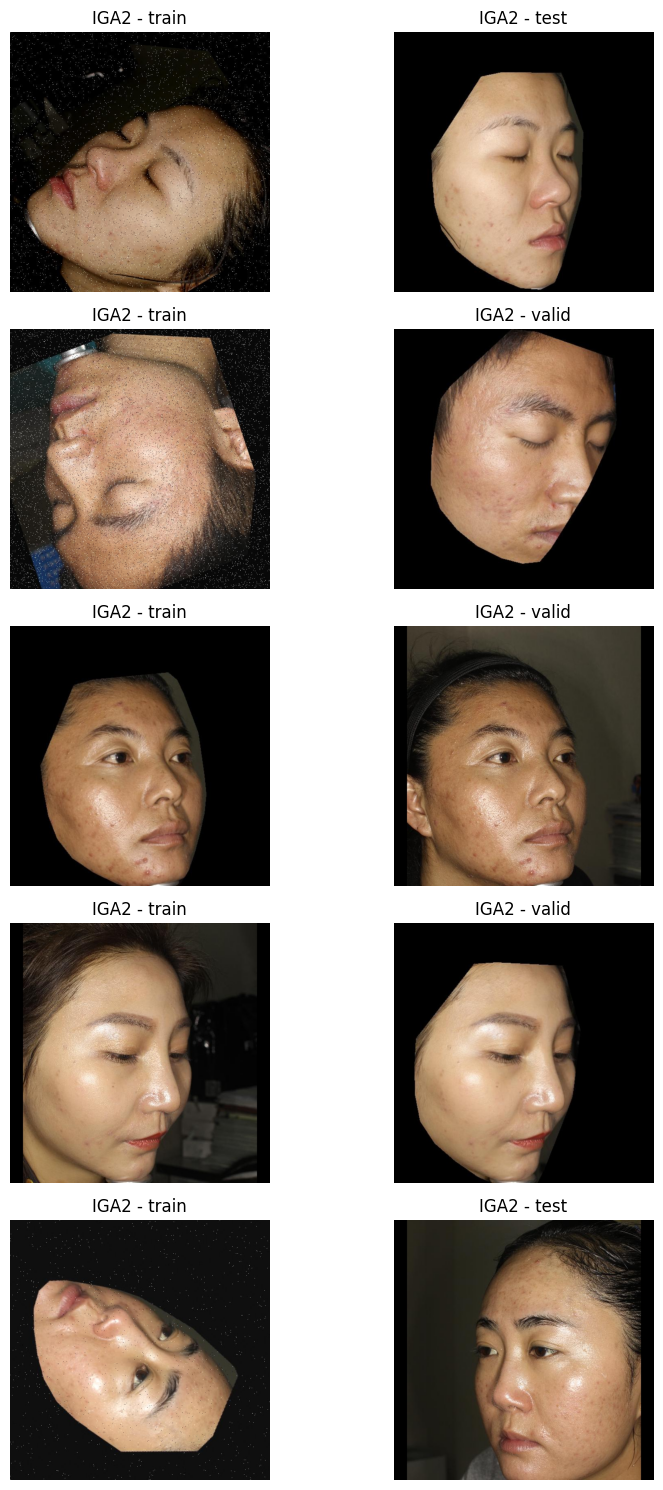

In [13]:

from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt
import random

# Mengelompokkan gambar berdasarkan nama sumber
kelompok = defaultdict(list)

for split in ["train", "valid", "test"]:
    for file in (data_dir / split).rglob("*"):
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:

            nama = file.name.split(".rf.")[0]
            kunci = (file.parent.name, nama)

            kelompok[kunci].append((split, file))

# Mencari nama yang muncul di split berbeda
duplikat = []

for nama, daftar in kelompok.items():
    split_unik = {item[0] for item in daftar}

    if len(split_unik) > 1:
        duplikat.append((nama, daftar))

print("Indikasi duplikat:", len(duplikat))

# Mengambil maksimal 5 contoh secara acak
sampel = random.Random(42).sample(
    duplikat, min(5, len(duplikat))
)

# Menampilkan pasangan gambar
fig, axes = plt.subplots(
    len(sampel), 2,
    figsize=(9, 3 * len(sampel)),
    squeeze=False
)

for i, (nama, daftar) in enumerate(sampel):

    # Mengambil satu gambar dari setiap split
    pilihan = {}

    for split, file in daftar:
        if split not in pilihan:
            pilihan[split] = file

    for j, (split, file) in enumerate(list(pilihan.items())[:2]):

        with Image.open(file) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(f"{nama[0]} - {split}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [14]:

from pathlib import Path
from collections import defaultdict
import shutil

# Dataset asli
data_asli = Path(dataset.location)

# Folder untuk dataset hasil perbaikan
data_bersih = data_asli.parent / (data_asli.name + "_clean")

# Mengelompokkan gambar berdasarkan sumbernya
kelompok = defaultdict(lambda: defaultdict(list))

for split in ["train", "valid", "test"]:
    for file in (data_asli / split).rglob("*"):

        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            nama_asli = file.name.split(".rf.")[0]
            kunci = (file.parent.name, nama_asli)

            kelompok[kunci][split].append(file)

# Menghindari pencampuran dengan hasil sebelumnya
if data_bersih.exists():
    raise FileExistsError(
        "Folder dataset bersih sudah ada. "
        "Gunakan hasil sebelumnya atau periksa folder tersebut."
    )

# Membuat dataset baru
for (kelas, nama), daftar in kelompok.items():

    # Memprioritaskan data testing dan validation
    if "test" in daftar:
        split = "test"
    elif "valid" in daftar:
        split = "valid"
    else:
        split = "train"

    # Pilih gambar sesuai split
    gambar = sorted(daftar[split])

    # Validation dan testing: satu gambar per sumber
    if split != "train":
        gambar = gambar[:1]

    # Menyalin gambar
    folder_tujuan = data_bersih / split / kelas
    folder_tujuan.mkdir(parents=True, exist_ok=True)

    for file in gambar:
        shutil.copy2(file, folder_tujuan / file.name)

print("Dataset baru berhasil dibuat!")
print("Lokasi:", data_bersih)


Dataset baru berhasil dibuat!
Lokasi: c:\Users\damar\KULIAH\S5\PemMes\testing\Acne-Severity-Classification-3_clean


In [15]:

import pandas as pd

hasil = []

for split in ["train", "valid", "test"]:
    folder = data_bersih / split

    for kelas in sorted(folder.iterdir()):
        if kelas.is_dir():

            gambar = [
                file for file in kelas.iterdir()
                if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]

            hasil.append({
                "Split": split,
                "Kelas": kelas.name,
                "Jumlah": len(gambar)
            })

df_bersih = pd.DataFrame(hasil)

distribusi_bersih = df_bersih.pivot(
    index="Kelas",
    columns="Split",
    values="Jumlah"
).fillna(0).astype(int)

display(distribusi_bersih)

print("Total gambar:", df_bersih["Jumlah"].sum())


Split,test,train,valid
Kelas,,,
IGA0,30,1113,78
IGA1,20,1257,48
IGA2,57,2346,122
IGA3,16,501,34
IGA4,11,390,29


Total gambar: 6052


In [16]:

# Menyimpan sumber gambar dan split
sumber = defaultdict(set)

for split in ["train", "valid", "test"]:
    for file in (data_bersih / split).rglob("*"):

        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            nama = file.name.split(".rf.")[0]
            kunci = (file.parent.name, nama)

            sumber[kunci].add(split)

# Menghitung sumber yang berada pada lebih dari satu split
duplikat = sum(
    len(splits) > 1
    for splits in sumber.values()
)

print("Indikasi kebocoran berdasarkan nama sumber:", duplikat)


Indikasi kebocoran berdasarkan nama sumber: 0


In [17]:
# Menggunakan dataset yang sudah dibersihkan
data_dir = data_bersih

print("Dataset yang digunakan:", data_dir)

Dataset yang digunakan: c:\Users\damar\KULIAH\S5\PemMes\testing\Acne-Severity-Classification-3_clean


*Membuat Model*

In [20]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Jumlah kelas sesuai dataset
jumlah_kelas = len(kelas)

# Membuat model CNN dari nol
model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    # Normalisasi gambar
    layers.Rescaling(1./255),

    # Convolution Block 1
    layers.Conv2D(16, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 4
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    # Bagian klasifikasi
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Output klasifikasi severity
    layers.Dense(jumlah_kelas, activation="softmax")
])

# Menampilkan arsitektur model
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 160, 160, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,981 (417.89 KB)

 Trainable params: 106,501 (416.02 KB)

 Non-trainable params: 480 (1.88 KB)

In [21]:

# Menentukan optimizer, loss, dan metrik evaluasi
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model berhasil dikompilasi!")


Model berhasil dikompilasi!


In [22]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Menghentikan training jika validation loss tidak membaik
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Menyimpan model terbaik
checkpoint = ModelCheckpoint(
    "dermascan_custom_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True
)

callbacks = [early_stop, checkpoint]


In [23]:

# Memulai proses training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)


Epoch 1/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 55s 300ms/step - accuracy: 0.4195 - loss: 1.2335 - val_accuracy: 0.3923 - val_loss: 1.8257
Epoch 2/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 46s 263ms/step - accuracy: 0.4421 - loss: 1.1107 - val_accuracy: 0.4051 - val_loss: 1.1787
Epoch 3/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 251ms/step - accuracy: 0.4575 - loss: 1.0787 - val_accuracy: 0.4855 - val_loss: 1.1547
Epoch 4/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 45s 255ms/step - accuracy: 0.4562 - loss: 1.0598 - val_accuracy: 0.3891 - val_loss: 1.2090
Epoch 5/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 50s 282ms/step - accuracy: 0.4651 - loss: 1.0401 - val_accuracy: 0.2637 - val_loss: 2.1798
Epoch 6/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 51s 290ms/step - accuracy: 0.4687 - loss: 1.0265 - val_accuracy: 0.4180 - val_loss: 1.3036
Epoch 7/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 49s 278ms/step - accuracy: 0.4733 - loss: 1.0170 - val_accuracy: 0.4405 - val_loss: 1.0766
Epoch 8/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 43s 245ms/step - accuracy: 0.4833 - loss: 0

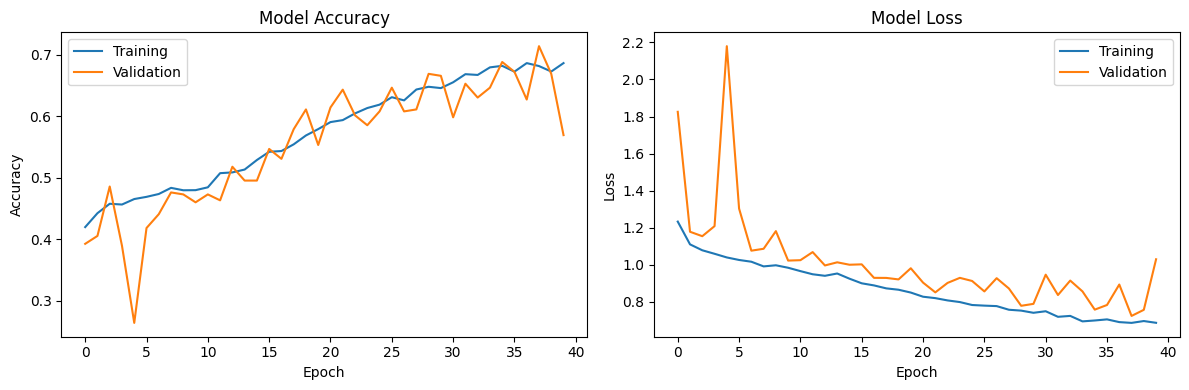

In [24]:

import matplotlib.pyplot as plt

# Mengambil riwayat training
akurasi = history.history["accuracy"]
val_akurasi = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Membuat grafik
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Grafik accuracy
axes[0].plot(akurasi, label="Training")
axes[0].plot(val_akurasi, label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Grafik loss
axes[1].plot(loss, label="Training")
axes[1].plot(val_loss, label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [25]:

import tensorflow as tf
import numpy as np

# Memuat model terbaik yang tersimpan
model_best = tf.keras.models.load_model(
    "dermascan_custom_cnn_best.keras"
)

# Mengevaluasi model pada data validation
val_loss, val_accuracy = model_best.evaluate(val_ds)

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.7138 - loss: 0.7247
Validation Loss     : 0.7247
Validation Accuracy : 0.7138
Validation Accuracy : 71.38%


In [26]:

from sklearn.metrics import classification_report

# Mengambil label asli dari data validation
y_true = np.concatenate([
    label.numpy() for gambar, label in val_ds
])

# Melakukan prediksi
y_pred_prob = model_best.predict(val_ds)

# Mengambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(y_pred_prob, axis=1)

# Menampilkan classification report
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(kelas)),
    target_names=kelas,
    zero_division=0
))


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
              precision    recall  f1-score   support

        IGA0       0.75      0.81      0.78        78
        IGA1       0.69      0.90      0.78        48
        IGA2       0.68      0.66      0.67       122
        IGA3       0.68      0.44      0.54        34
        IGA4       0.83      0.69      0.75        29

    accuracy                           0.71       311
   macro avg       0.73      0.70      0.70       311
weighted avg       0.71      0.71      0.71       311



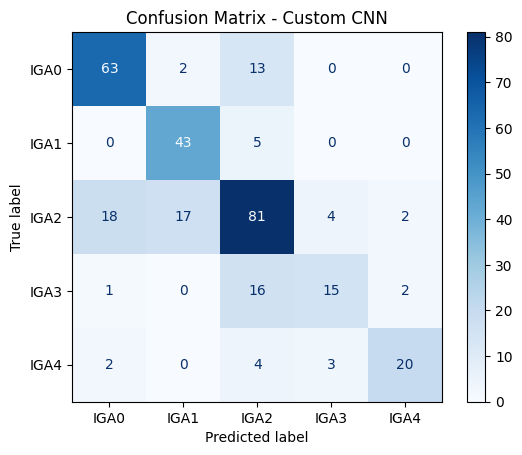

In [27]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Membuat confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(kelas))
)

# Menampilkan confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=kelas
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix - Custom CNN")
plt.show()


In [28]:

# Menghitung jumlah gambar training setiap kelas
jumlah_gambar = []

for nama_kelas in kelas:
    folder = data_dir / "train" / nama_kelas

    jumlah = len([
        f for f in folder.iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    jumlah_gambar.append(jumlah)

# Menghitung bobot setiap kelas
total = sum(jumlah_gambar)
jumlah_kelas = len(kelas)

class_weight = {}

for i, jumlah in enumerate(jumlah_gambar):
    class_weight[i] = total / (jumlah_kelas * jumlah)

# Menampilkan hasil
for i, nama_kelas in enumerate(kelas):
    print(
        f"{nama_kelas}: {jumlah_gambar[i]} gambar, "
        f"bobot = {class_weight[i]:.3f}"
    )


IGA0: 1113 gambar, bobot = 1.008
IGA1: 1257 gambar, bobot = 0.892
IGA2: 2346 gambar, bobot = 0.478
IGA3: 501 gambar, bobot = 2.238
IGA4: 390 gambar, bobot = 2.875


In [29]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Menyalin arsitektur CNN tanpa menyalin bobot terlatih
model_v2 = tf.keras.models.clone_model(model_best)

# Compile model baru
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Callback eksperimen kedua
callbacks_v2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "dermascan_custom_cnn_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Model eksperimen kedua siap!")


Model eksperimen kedua siap!


In [30]:

# Training eksperimen kedua
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weight,
    callbacks=callbacks_v2
)


Epoch 1/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 47s 255ms/step - accuracy: 0.3610 - loss: 1.3459 - val_accuracy: 0.1158 - val_loss: 1.7845
Epoch 2/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 46s 263ms/step - accuracy: 0.4127 - loss: 1.1875 - val_accuracy: 0.2347 - val_loss: 1.6440
Epoch 3/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 83s 269ms/step - accuracy: 0.4134 - loss: 1.1503 - val_accuracy: 0.3794 - val_loss: 1.2479
Epoch 4/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 47s 267ms/step - accuracy: 0.4254 - loss: 1.1103 - val_accuracy: 0.3987 - val_loss: 1.3164
Epoch 5/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 47s 267ms/step - accuracy: 0.4314 - loss: 1.0942 - val_accuracy: 0.3441 - val_loss: 1.5134
Epoch 6/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 46s 260ms/step - accuracy: 0.4421 - loss: 1.0825 - val_accuracy: 0.4051 - val_loss: 1.2532
Epoch 7/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 50s 283ms/step - accuracy: 0.4334 - loss: 1.0767 - val_accuracy: 0.3248 - val_loss: 1.7049
Epoch 8/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 46s 259ms/step - accuracy: 0.4434 - loss: 1

In [32]:

from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Memuat model terbaik eksperimen kedua
model_v2_best = tf.keras.models.load_model(
    "dermascan_custom_cnn_v2.keras"
)

# Mengambil label asli
y_true = np.concatenate([
    y.numpy() for x, y in val_ds
])

# Prediksi kedua model
pred_v1 = np.argmax(model_best.predict(val_ds), axis=1)
pred_v2 = np.argmax(model_v2_best.predict(val_ds), axis=1)

# Menghitung macro F1
f1_v1 = f1_score(y_true, pred_v1, average="macro")
f1_v2 = f1_score(y_true, pred_v2, average="macro")

# Menghitung accuracy
acc_v1 = np.mean(y_true == pred_v1)
acc_v2 = np.mean(y_true == pred_v2)

# Tabel perbandingan
perbandingan = pd.DataFrame({
    "Model": ["Custom CNN V1", "Custom CNN V2"],
    "Accuracy": [acc_v1, acc_v2],
    "Macro F1": [f1_v1, f1_v2]
})

display(perbandingan)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step


,Model,Accuracy,Macro F1
0,Custom CNN V1,0.713826,0.704445
1,Custom CNN V2,0.530547,0.539358


In [31]:

import numpy as np

# Menghitung jumlah epoch yang dijalankan
total_epoch = len(history_v2.history["loss"])

# Mencari epoch dengan validation loss terbaik
best_epoch = np.argmin(
    history_v2.history["val_loss"]
) + 1

# Mengambil hasil terbaik
best_loss = min(history_v2.history["val_loss"])

print("Total epoch dijalankan:", total_epoch)
print("Epoch terbaik:", best_epoch)
print("Validation loss terbaik:", round(best_loss, 4))
print("EarlyStopping:", total_epoch < 40)


Total epoch dijalankan: 25
Epoch terbaik: 17
Validation loss terbaik: 0.9847
EarlyStopping: True


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step
Classification Report CNN V2:
              precision    recall  f1-score   support

        IGA0       0.56      0.88      0.69        78
        IGA1       0.45      0.88      0.59        48
        IGA2       0.57      0.07      0.12       122
        IGA3       0.51      0.68      0.58        34
        IGA4       0.66      0.79      0.72        29

    accuracy                           0.53       311
   macro avg       0.55      0.66      0.54       311
weighted avg       0.55      0.53      0.44       311



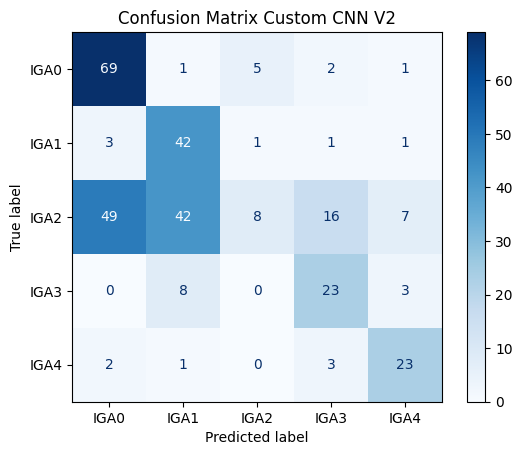

In [33]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Prediksi model V2
y_pred_v2 = np.argmax(
    model_v2_best.predict(val_ds),
    axis=1
)

# Menampilkan hasil evaluasi setiap kelas
print("Classification Report CNN V2:")
print(classification_report(
    y_true,
    y_pred_v2,
    target_names=kelas,
    zero_division=0
))

# Menampilkan confusion matrix
cm_v2 = confusion_matrix(y_true, y_pred_v2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix Custom CNN V2")
plt.show()


In [34]:

# Memperhalus class weight menggunakan akar kuadrat
class_weight_v3 = {}

for i, bobot in class_weight.items():
    class_weight_v3[i] = bobot ** 0.5

# Menampilkan perbandingan bobot
for i, nama in enumerate(kelas):
    print(
        f"{nama}: "
        f"V2 = {class_weight[i]:.3f}, "
        f"V3 = {class_weight_v3[i]:.3f}"
    )


IGA0: V2 = 1.008, V3 = 1.004
IGA1: V2 = 0.892, V3 = 0.945
IGA2: V2 = 0.478, V3 = 0.691
IGA3: V2 = 2.238, V3 = 1.496
IGA4: V2 = 2.875, V3 = 1.696


In [35]:

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Mengatur random seed
tf.keras.utils.set_random_seed(42)

# Membuat model baru dengan arsitektur yang sama
model_v3 = tf.keras.models.clone_model(model_best)

# Compile model
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Callback untuk model V3
callbacks_v3 = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "dermascan_custom_cnn_v3.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Model V3 siap untuk training!")


Model V3 siap untuk training!


In [36]:

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weight_v3,
    callbacks=callbacks_v3
)


Epoch 1/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 43s 232ms/step - accuracy: 0.4097 - loss: 1.2375 - val_accuracy: 0.1479 - val_loss: 1.7939
Epoch 2/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 44s 249ms/step - accuracy: 0.4395 - loss: 1.1190 - val_accuracy: 0.3633 - val_loss: 1.3132
Epoch 3/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 79s 234ms/step - accuracy: 0.4407 - loss: 1.0797 - val_accuracy: 0.4277 - val_loss: 1.2587
Epoch 4/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 41s 229ms/step - accuracy: 0.4500 - loss: 1.0721 - val_accuracy: 0.4502 - val_loss: 1.3336
Epoch 5/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 39s 222ms/step - accuracy: 0.4641 - loss: 1.0403 - val_accuracy: 0.3826 - val_loss: 1.4169
Epoch 6/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 45s 254ms/step - accuracy: 0.4605 - loss: 1.0305 - val_accuracy: 0.4309 - val_loss: 1.0524
Epoch 7/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 40s 226ms/step - accuracy: 0.4555 - loss: 1.0143 - val_accuracy: 0.4148 - val_loss: 1.1265
Epoch 8/40
176/176 ━━━━━━━━━━━━━━━━━━━━ 42s 238ms/step - accuracy: 0.4675 - loss: 0

In [37]:

import numpy as np
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Memuat model terbaik V3
model_v3_best = tf.keras.models.load_model(
    "dermascan_custom_cnn_v3.keras"
)

# Prediksi validation
pred_v3 = np.argmax(
    model_v3_best.predict(val_ds),
    axis=1
)

# Menampilkan metrik
print("Accuracy:", accuracy_score(y_true, pred_v3))
print("Macro F1:", f1_score(y_true, pred_v3, average="macro"))

print("\nClassification Report CNN V3:")
print(classification_report(
    y_true,
    pred_v3,
    labels=range(len(kelas)),
    target_names=kelas,
    zero_division=0
))


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step
Accuracy: 0.6720257234726688
Macro F1: 0.6856400615974367

Classification Report CNN V3:
              precision    recall  f1-score   support

        IGA0       0.74      0.72      0.73        78
        IGA1       0.69      0.75      0.72        48
        IGA2       0.67      0.57      0.62       122
        IGA3       0.49      0.79      0.61        34
        IGA4       0.83      0.69      0.75        29

    accuracy                           0.67       311
   macro avg       0.69      0.71      0.69       311
weighted avg       0.69      0.67      0.67       311



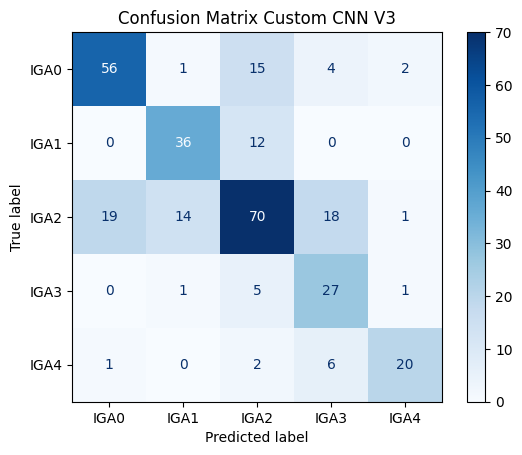

In [38]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Membuat confusion matrix model V3
cm_v3 = confusion_matrix(
    y_true,
    pred_v3,
    labels=range(len(kelas))
)

# Menampilkan confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_v3,
    display_labels=kelas
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix Custom CNN V3")
plt.show()


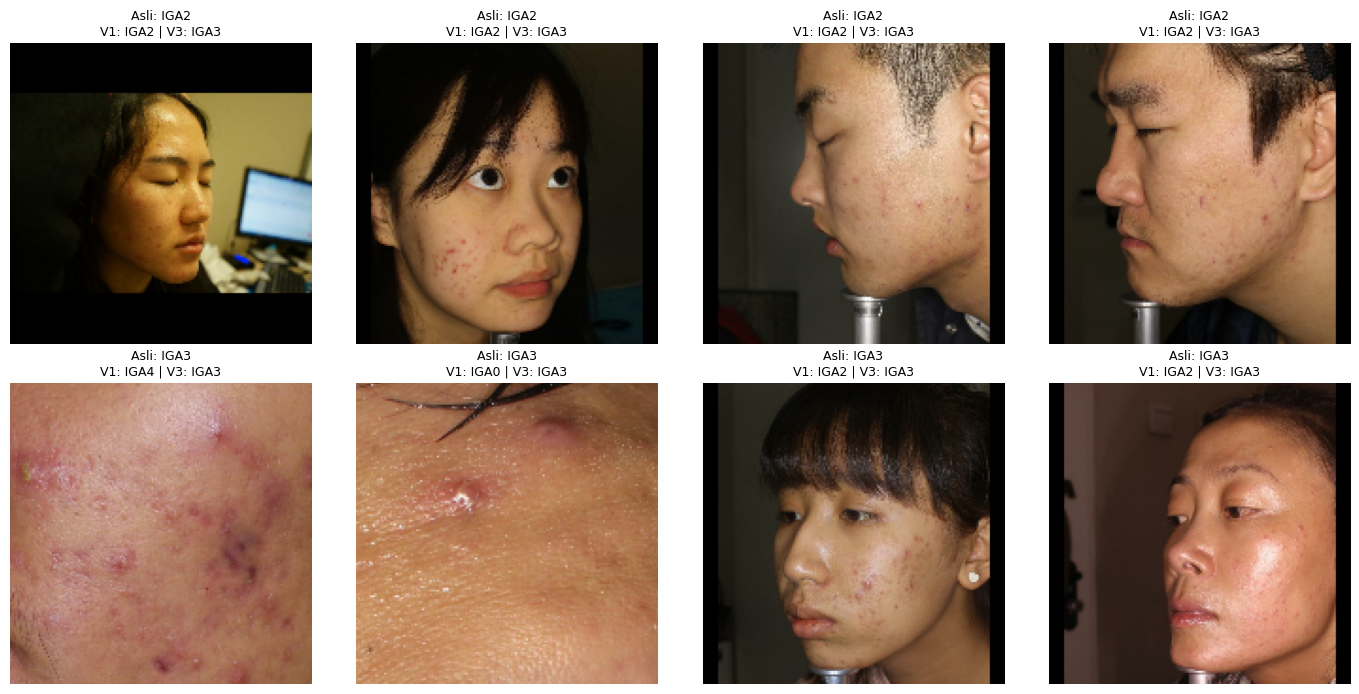

In [39]:

import numpy as np
import matplotlib.pyplot as plt

# Mengambil seluruh gambar validation
gambar_val = np.concatenate([
    gambar.numpy() for gambar, label in val_ds
]).astype("uint8")

# Kasus 1: IGA2 benar pada V1, tetapi diprediksi IGA3 oleh V3
kasus_iga2 = np.where(
    (y_true == kelas.index("IGA2")) &
    (pred_v1 == kelas.index("IGA2")) &
    (pred_v3 == kelas.index("IGA3"))
)[0][:4]

# Kasus 2: IGA3 salah pada V1, tetapi benar pada V3
kasus_iga3 = np.where(
    (y_true == kelas.index("IGA3")) &
    (pred_v1 != kelas.index("IGA3")) &
    (pred_v3 == kelas.index("IGA3"))
)[0][:4]

# Menampilkan gambar perbandingan
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for baris, kasus in enumerate([kasus_iga2, kasus_iga3]):
    for kolom, idx in enumerate(kasus):
        ax = axes[baris, kolom]

        ax.imshow(gambar_val[idx])
        ax.set_title(
            f"Asli: {kelas[y_true[idx]]}\n"
            f"V1: {kelas[pred_v1[idx]]} | "
            f"V3: {kelas[pred_v3[idx]]}",
            fontsize=9
        )

    for ax in axes[baris]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [40]:

import numpy as np
import pandas as pd

# Mengambil probabilitas prediksi kedua model
prob_v1 = model_best.predict(val_ds, verbose=0)
prob_v3 = model_v3_best.predict(val_ds, verbose=0)

# Mengambil indeks 8 gambar dari Cell 36
indeks = list(kasus_iga2) + list(kasus_iga3)

hasil = []

for idx in indeks:
    # Kelas prediksi
    prediksi_v1 = np.argmax(prob_v1[idx])
    prediksi_v3 = np.argmax(prob_v3[idx])

    # Skor tertinggi setiap model
    skor_v1 = np.max(prob_v1[idx])
    skor_v3 = np.max(prob_v3[idx])

    hasil.append({
        "Label Asli": kelas[y_true[idx]],
        "Prediksi V1": kelas[prediksi_v1],
        "Skor V1": f"{skor_v1:.2%}",
        "Prediksi V3": kelas[prediksi_v3],
        "Skor V3": f"{skor_v3:.2%}"
    })

display(pd.DataFrame(hasil))


,Label Asli,Prediksi V1,Skor V1,Prediksi V3,Skor V3
0,IGA2,IGA2,64.30%,IGA3,51.95%
1,IGA2,IGA2,55.71%,IGA3,68.02%
2,IGA2,IGA2,72.16%,IGA3,70.79%
3,IGA2,IGA2,66.61%,IGA3,65.98%
4,IGA3,IGA4,75.64%,IGA3,61.33%
5,IGA3,IGA0,38.17%,IGA3,95.15%
6,IGA3,IGA2,75.11%,IGA3,63.42%
7,IGA3,IGA2,46.83%,IGA3,50.24%


In [41]:

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Mengambil label asli data testing
y_test = np.concatenate([
    label.numpy() for gambar, label in test_ds
])

# Melakukan prediksi menggunakan model V1 terbaik
prob_test = model_best.predict(test_ds)

# Mengambil kelas dengan probabilitas tertinggi
pred_test = np.argmax(prob_test, axis=1)

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, pred_test)
macro_f1 = f1_score(y_test, pred_test, average="macro")

print(f"Testing Accuracy: {accuracy:.4f}")
print(f"Testing Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    pred_test,
    labels=range(len(kelas)),
    target_names=kelas,
    zero_division=0
))


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Testing Accuracy: 0.7463
Testing Macro F1: 0.7659

Classification Report:
              precision    recall  f1-score   support

        IGA0       0.73      0.90      0.81        30
        IGA1       0.61      0.95      0.75        20
        IGA2       0.84      0.56      0.67        57
        IGA3       0.85      0.69      0.76        16
        IGA4       0.73      1.00      0.85        11

    accuracy                           0.75       134
   macro avg       0.75      0.82      0.77       134
weighted avg       0.77      0.75      0.74       134



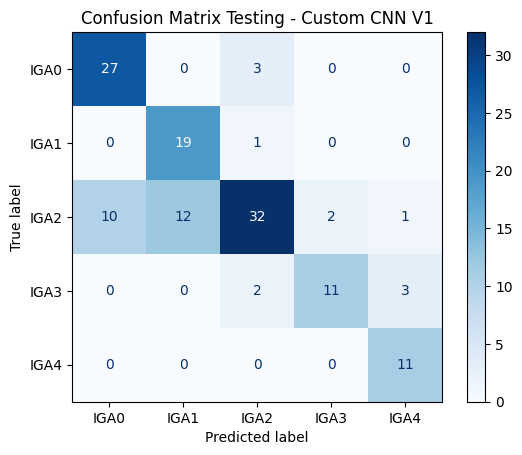

In [42]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Membuat confusion matrix
cm_test = confusion_matrix(
    y_test,
    pred_test,
    labels=range(len(kelas))
)

# Menampilkan hasil
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix Testing - Custom CNN V1")
plt.show()


In [43]:

import tensorflow as tf
from pathlib import Path

# Memuat model CNN V1 terbaik
model_final = tf.keras.models.load_model(
    "dermascan_custom_cnn_best.keras"
)

# Mengonversi model menjadi TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model_final)
tflite_model = converter.convert()

# Menyimpan model TFLite
model_path = Path("dermascan_custom_cnn.tflite")
model_path.write_bytes(tflite_model)

print("Model berhasil dikonversi!")
print("Lokasi:", model_path.resolve())
print("Ukuran:", round(model_path.stat().st_size / 1024, 2), "KB")


INFO:tensorflow:Assets written to: C:\Users\damar\AppData\Local\Temp\tmpd0ho9jcv\assets


INFO:tensorflow:Assets written to: C:\Users\damar\AppData\Local\Temp\tmpd0ho9jcv\assets


Saved artifact at 'C:\Users\damar\AppData\Local\Temp\tmpd0ho9jcv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2052816505136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816510064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816587056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816589168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816516752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816584768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816600608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816591632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816753360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2052816751600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  205281

In [44]:

# Menyimpan nama kelas sesuai urutan training
with open("labels.txt", "w") as file:
    for nama in kelas:
        file.write(nama + "\n")

print("Label berhasil disimpan:")
print(kelas)


Label berhasil disimpan:
['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']


In [45]:

import numpy as np

# Memuat model TFLite
interpreter = tf.lite.Interpreter(
    model_path=str(model_path)
)
interpreter.allocate_tensors()

# Mengambil informasi input dan output
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input shape:", input_details[0]["shape"])
print("Input type:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])

# Mengambil satu gambar testing
gambar, label = next(iter(test_ds))
sampel = gambar[:1].numpy().astype(np.float32)

# Prediksi dengan model Keras
hasil_keras = model_final.predict(sampel, verbose=0)

# Prediksi dengan model TFLite
interpreter.set_tensor(input_details[0]["index"], sampel)
interpreter.invoke()
hasil_tflite = interpreter.get_tensor(
    output_details[0]["index"]
)

# Membandingkan hasil prediksi
print("\nPrediksi Keras:",
      kelas[np.argmax(hasil_keras)])

print("Prediksi TFLite:",
      kelas[np.argmax(hasil_tflite)])

print("Selisih probabilitas terbesar:",
      np.max(np.abs(hasil_keras - hasil_tflite)))


    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    


Input shape: [  1 160 160   3]
Input type: <class 'numpy.float32'>
Output shape: [1 5]

Prediksi Keras: IGA0
Prediksi TFLite: IGA0
Selisih probabilitas terbesar: 1.1920929e-07
